# 09.2 · Solutions

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/cloudops-one/training-ai-ml/blob/main/modules/09-nlp-genai/02-sentiment-classifier/solutions.ipynb)

In [1]:
# --- data helper: works locally and on Colab -------------------------------
from pathlib import Path
import urllib.request

def data_path(name):
    """Return a local path to data/<name>, downloading from GitHub on Colab."""
    for parent in [Path.cwd(), *Path.cwd().parents]:
        candidate = parent / "data" / name
        if candidate.exists():
            return candidate
    url = f"https://raw.githubusercontent.com/cloudops-one/training-ai-ml/main/data/{name}"
    dest = Path(name)
    if not dest.exists():
        urllib.request.urlretrieve(url, dest)
    return dest

import os, logging, warnings
os.environ["HF_HUB_DISABLE_PROGRESS_BARS"] = "1"
os.environ["HF_HUB_VERBOSITY"] = "error"
os.environ["TOKENIZERS_PARALLELISM"] = "false"
logging.getLogger("torch.distributed.elastic.multiprocessing.redirects").setLevel(logging.ERROR)
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import sys
sys.path.insert(0, str(data_path("download.py").parent))

## Exercise 1

- *good good bad*: $1 + 1 - 2 = 0$, $\sigma(0) = 0.5$. Undecided.
- *not not bad*: $-2 - 2 - 2 = -6$, $\sigma(-6) = 0.002$. Double negation reads as very negative.
- *not bad* with the bigram: $-2 - 2 + 5 = +1$, $\sigma(1) = 0.731$. Positive, but only because we gave the bigram a vote bigger than both single words together. In the real model it learned only +0.49.

In [2]:
votes = {"great": 2, "good": 1, "not": -2, "bad": -2}

def toy_score(review):
    words = review.lower().replace(",", "").split()
    z = sum(votes.get(w, 0) for w in words)
    return z, 1 / (1 + np.exp(-z))

for review in ["good good bad", "not not bad"]:
    z, p = toy_score(review)
    print(f"{review:14} z = {z:+d}   P(positive) = {p:.3f}")
z = votes["not"] + votes["bad"] + 5
print("not bad with bigram:", z, round(1 / (1 + np.exp(-z)), 3))

good good bad  z = +0   P(positive) = 0.500
not not bad    z = -6   P(positive) = 0.002
not bad with bigram: 1 0.731


## Exercise 2

In [3]:
from download import load_reviews
from sklearn.model_selection import train_test_split

reviews = load_reviews()          # first run downloads one 117 MB file, then cached
train, test = train_test_split(reviews, test_size=0.2, random_state=42, stratify=reviews["label"])
print(f"{len(reviews):,} reviews ({reviews['label'].mean():.0%} positive): "
      f"train {len(train):,} / test {len(test):,}")
reviews[["text", "label"]].head()

10,000 reviews (50% positive): train 8,000 / test 2,000


,text,label
0,"Great Book, Must read! Ramon found the fabulou...",1
1,A leaker! This is the second generation of the...,0
2,Not For the Professional Cook. Henckels are we...,0
3,Arg! I'd like to see Robert Jordan put to the ...,0
4,"If I could give this minus 5 stars, I'd give i...",0


In [4]:
from sklearn.pipeline import make_pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression

def text_model(**vectoriser_settings):
    return make_pipeline(TfidfVectorizer(**vectoriser_settings), LogisticRegression(max_iter=1000))

model = text_model(ngram_range=(1, 2), min_df=2).fit(train["text"], train["label"])

from sklearn.metrics import accuracy_score
for min_df in [1, 2, 5, 20]:
    m = text_model(ngram_range=(1, 2), min_df=min_df).fit(train["text"], train["label"])
    vocab = len(m.named_steps["tfidfvectorizer"].vocabulary_)
    print(f"min_df={min_df:>2}: {vocab:>7,} columns, accuracy {accuracy_score(test['label'], m.predict(test['text'])):.1%}")

min_df= 1: 285,773 columns, accuracy 87.4%


min_df= 2:  66,583 columns, accuracy 88.4%


min_df= 5:  21,555 columns, accuracy 88.1%


min_df=20:   5,071 columns, accuracy 88.3%


The vocabulary shrinks dramatically while accuracy barely moves: most of the rare columns carry no reliable signal.

## Exercise 3

In [5]:
mine = ["The fairy lights are not bright enough, but they look lovely.",
        "I can't fault this cake stand at all.",
        "Brilliant, the mug arrived in three pieces.",
        "No complaints whatsoever.",
        "Never had a teapot pour so badly."]
for review, p in zip(mine, model.predict_proba(mine)[:, 1]):
    print(f"P(positive) = {p:.3f}   {review}")

P(positive) = 0.306   The fairy lights are not bright enough, but they look lovely.
P(positive) = 0.318   I can't fault this cake stand at all.
P(positive) = 0.589   Brilliant, the mug arrived in three pieces.
P(positive) = 0.402   No complaints whatsoever.
P(positive) = 0.334   Never had a teapot pour so badly.


Three of the four clear-cut reviews fool it. *"I can't fault this cake stand"* (0.32) and *"No complaints whatsoever"* (0.40) are praise built from negative words; *"Brilliant, the mug arrived in three pieces"* (0.59) is sarcasm. Only *"Never had a teapot pour so badly"* (0.33) is right, and for the easy reason: it is full of negative words. The fairy-light review is genuinely mixed, and 0.31 is a fair reading. The pattern: negation words (*can't*, *no*, *never*) push towards negative whatever follows, and sarcasm goes undetected.

## Exercise 4

  100 training reviews: 63.8%
  500 training reviews: 78.0%


 2000 training reviews: 84.4%


 8000 training reviews: 88.4%


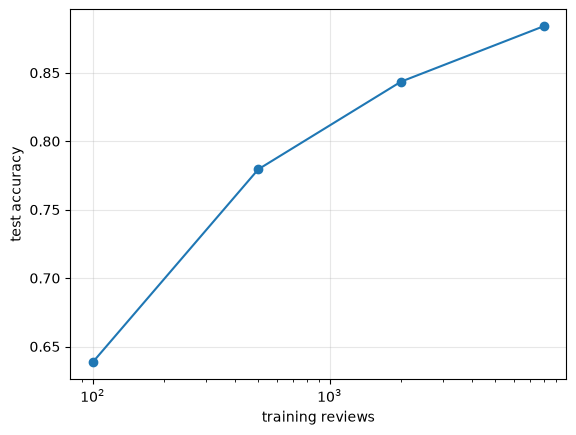

In [6]:
sizes = [100, 500, 2000, 8000]
acc = []
for n in sizes:
    m = text_model(ngram_range=(1, 2), min_df=2).fit(train["text"].iloc[:n], train["label"].iloc[:n])
    acc.append(accuracy_score(test["label"], m.predict(test["text"])))
    print(f"{n:>5} training reviews: {acc[-1]:.1%}")
plt.semilogx(sizes, acc, "o-"); plt.xlabel("training reviews"); plt.ylabel("test accuracy")
plt.grid(alpha=.3); plt.show()

With 100 reviews the model reaches only 63.8%; it needs thousands of labelled examples to learn reliable votes for enough words. 09.3 shows a method that does much better with little data.